In [1]:
# Importing Libraries
import ast
import pandas as pd
import seaborn as sns
from datasets import load_dataset
import matplotlib.pyplot as plt  

# Loading Data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

# Data Cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

Filter for US Data Analyst roles

In [23]:
df_DA_US = df[(df['job_title_short'] =='Data Analyst') & (df['job_country']== 'United States')]

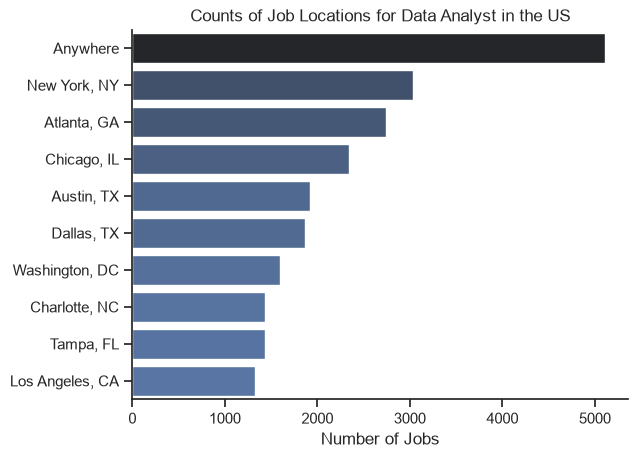

In [11]:
df_plot = df_DA_US['job_location'].value_counts(ascending= False).head(10).to_frame()
sns.set_theme(style= 'ticks')
sns.barplot(df_plot, x='count' , y = 'job_location' , hue = 'count' , palette= 'dark:b_r', legend=False)
sns.despine()
plt.title('Counts of Job Locations for Data Analyst in the US')
plt.xlabel('Number of Jobs')
plt.ylabel('')
plt.show()

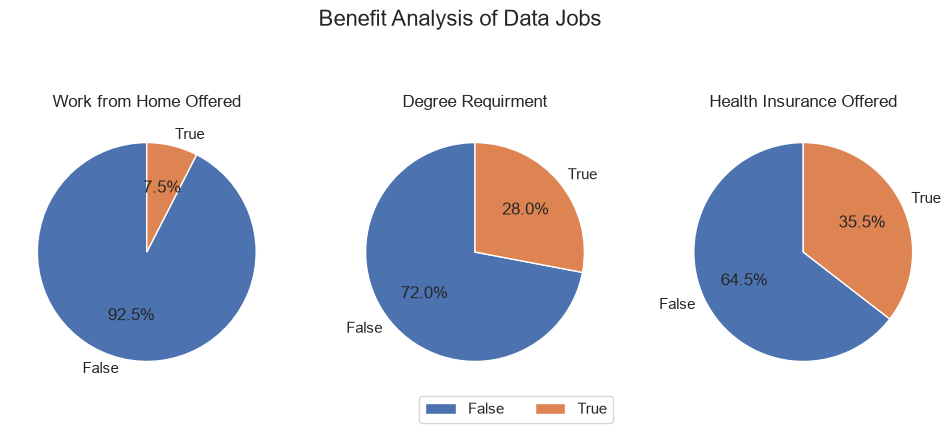

In [16]:
# rewrite the above with a for loop
dict_column = {
    'job_work_from_home': 'Work from Home Offered',
    'job_no_degree_mention':'Degree Requirment',
    'job_health_insurance':'Health Insurance Offered'
}
fig , ax = plt.subplots(1, 3) 
fig.set_size_inches((12, 5))
for i , (column, title) in enumerate(dict_column.items()):
    ax[i].pie(df_DA_US[column].value_counts(), labels=['False', 'True'] , startangle = 90, autopct= '%1.1f%%' )
    ax[i].set_title(title)
plt.suptitle('Benefit Analysis of Data Jobs', fontsize=16)
plt.legend(loc='upper center', bbox_to_anchor=(-0.55, 0), ncol=2)
plt.show()


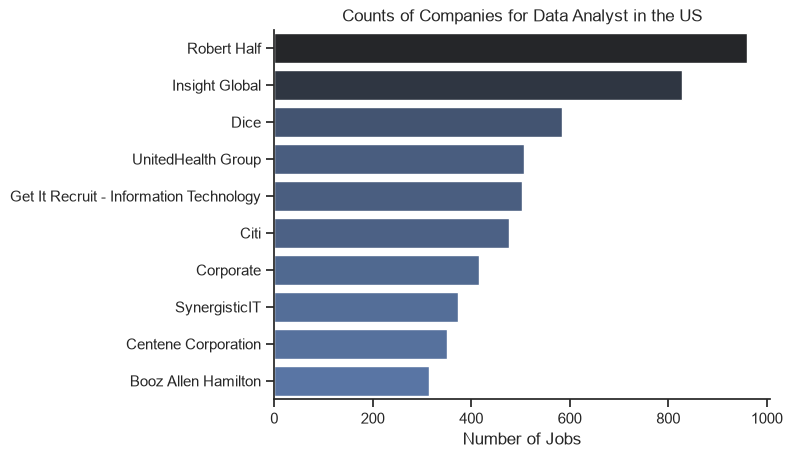

In [21]:
df_plot = df_DA_US['company_name'].value_counts(ascending=False).head(10).to_frame()
sns.set_theme(style= 'ticks')
sns.barplot(df_plot, x = 'count', y= 'company_name', hue= 'count', palette='dark:b_r', legend= False)
sns.despine()
plt.xlabel('Number of Jobs')
plt.ylabel('')
plt.title('Counts of Companies for Data Analyst in the US')
plt.show()